In [152]:
import warnings
from datetime import timedelta

from src.data.datemath import from_ymd

import pandas as pd
import statsmodels.api as sm
from statsmodels.iolib.summary2 import summary_col
from tabulate import tabulate
import numpy as np
import pyfixest as pf
import plotly.express as px
import geopandas as gpd
from functools import reduce, partial


In [2]:
train_panel_in = "../../../data/final/train_panel.parquet"
bike_panel_in = "../../../data/final/bike_panel.parquet"
uber_panel_in = "../../../data/final/uber_panel.parquet"
train_stations_in = "../../../data/interim/train_stations.geojson"

did_out = "../../../reports/replication/did_simple.md"

In [3]:
train_panel = pd.read_parquet(train_panel_in)
bike_panel = pd.read_parquet(bike_panel_in)
uber_panel = pd.read_parquet(uber_panel_in)
train_stations = gpd.read_file(train_stations_in)

In [4]:
panel = pd.concat([train_panel, bike_panel, uber_panel],
                     keys=['train', 'bike', 'uber'], names=['transit']).reset_index('transit')
assert not any(panel.groupby('id')['transit'].nunique() > 1), 'ids must be unique across transits'

# Preprocessing

In [5]:
# The DNC was only 4 days, not even friday. So weekends are uninformative.
def drop_weekends(df):
    df = df[(0 <= df['dotw']) & (df['dotw'] <= 3)]
    return df

In [6]:
# The Damen stop opened one week before the convention. So its potentially correlated.
def drop_damen(df):
    damen_mask = (train_stations['line'] == 'green') & (train_stations['station_name'] == 'Damen')
    damen_id = train_stations[damen_mask]['map_id'].iloc[0]
    damen_mask = (df['id'] == damen_id)
    df = df[~damen_mask]
    return df

In [7]:
def drop_non_stadium(df):
    dists = ['distance_HYATT_REGENCY_MCCORMICK_PLACE', 'distance_UNITED_CENTER',
        'distance_SOLDIER_FIELD', 'distance_WRIGLEY_FIELD', 'distance_GUARANTEED_RATE_FIELD']
    dists = [df[d] <= 1600 for d in dists]
    mask = reduce(lambda a,b: a | b, dists)
    df = df[mask]
    return df

In [8]:
def pipes(funcs):
    return lambda df: reduce(lambda acc, f: f(acc), funcs, df)

# DiffNDiff

In [96]:
def model_did(df, treat_col="treat", fe="id + time"):
    df = df.sort_values('date')
    unit_obs = df.groupby('id').size()
    df['weight'] = df['id'].map(unit_obs).apply(lambda x: 1/x)
    formula = f"""logrides ~ {treat_col} : i(transit, ref='uber') + {treat_col} | {fe}"""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        did_model = pf.feols(formula, df, weights='weight', vcov={"CRV1": "id + time"})
    return did_model

/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/did/visualize.py:209: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(get_treatment_start)


<Axes: title={'center': 'Outcome over Time with Treatment Effect'}, xlabel='time', ylabel='logrides'>

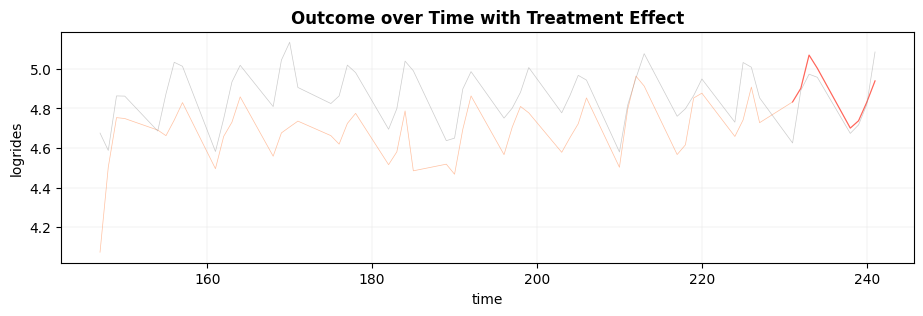

In [38]:
spec1_model = model_did(pipes([drop_weekends, drop_non_stadium])(panel))
spec1_model.summary()

In [19]:
spec2_model = model_did(pipes([drop_weekends, drop_damen])(panel))
spec2_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time
sample: None = all
Inference:  CRV1
Observations:  110010

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.214 |        0.087 |     2.457 |      0.017 |  0.039 |   0.388 |
| treat:transit::bike  |      0.071 |        0.106 |     0.672 |      0.505 | -0.141 |   0.282 |
| treat:transit::train |      0.033 |        0.157 |     0.209 |      0.835 | -0.283 |   0.348 |
---
RMSE: 0.054 R2: 0.972 R2 Within: 0.001 


/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 151 singleton fixed effect(s) dropped from the model.
  warnings.warn(
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: divide by zero encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: overflow encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: invalid value encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()


In [25]:
spec3_model = model_did(pipes([drop_weekends])(panel), fe="id + time^transit")
spec3_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time^transit
sample: None = all
Inference:  CRV1
Observations:  110026

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.231 |        0.082 |     2.815 |      0.007 |  0.067 |   0.396 |
| treat:transit::bike  |      0.029 |        0.088 |     0.326 |      0.745 | -0.147 |   0.204 |
| treat:transit::train |      0.193 |        0.152 |     1.274 |      0.208 | -0.111 |   0.497 |
---
RMSE: 0.053 R2: 0.973 R2 Within: 0.001 


/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 151 singleton fixed effect(s) dropped from the model.
  warnings.warn(
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: divide by zero encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: overflow encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: invalid value encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()


In [26]:
spec4_model = model_did(pipes([drop_weekends, drop_damen])(panel), fe="id + time^transit")
spec4_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time^transit
sample: None = all
Inference:  CRV1
Observations:  110010

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.231 |        0.082 |     2.815 |      0.007 |  0.067 |   0.396 |
| treat:transit::bike  |      0.029 |        0.088 |     0.326 |      0.745 | -0.147 |   0.204 |
| treat:transit::train |      0.093 |        0.147 |     0.630 |      0.531 | -0.202 |   0.388 |
---
RMSE: 0.053 R2: 0.973 R2 Within: 0.001 


/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 151 singleton fixed effect(s) dropped from the model.
  warnings.warn(
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: divide by zero encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: overflow encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: invalid value encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()


In [22]:
spec5_model = model_did(pipes([drop_weekends, drop_non_stadium])(panel))
spec5_model.summary()

/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: divide by zero encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: overflow encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: invalid value encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()


###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time
sample: None = all
Inference:  CRV1
Observations:  13127

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.160 |        0.080 |     1.988 |      0.052 | -0.001 |   0.321 |
| treat:transit::bike  |      0.071 |        0.105 |     0.670 |      0.506 | -0.141 |   0.282 |
| treat:transit::train |      0.130 |        0.159 |     0.816 |      0.418 | -0.189 |   0.448 |
---
RMSE: 0.049 R2: 0.956 R2 Within: 0.006 


In [32]:
spec6_model = model_did(pipes([drop_weekends, drop_non_stadium])(panel), fe="id + time^transit")
spec6_model.summary()

###

Estimation:  OLS
Dep. var.: logrides, Fixed effects: id + time^transit
sample: None = all
Inference:  CRV1
Observations:  13127

| Coefficient          |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:---------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treat                |      0.270 |        0.086 |     3.134 |      0.003 |  0.097 |   0.443 |
| treat:transit::bike  |     -0.143 |        0.105 |    -1.366 |      0.178 | -0.354 |   0.067 |
| treat:transit::train |      0.138 |        0.151 |     0.919 |      0.362 | -0.163 |   0.440 |
---
RMSE: 0.048 R2: 0.959 R2 Within: 0.007 


/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: divide by zero encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: overflow encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()
/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/estimation/models/feols_.py:594: RuntimeWarning: invalid value encountered in matmul
  self._u_hat = self._Y.flatten() - (self._X @ self._beta_hat).flatten()


In [33]:
pf.etable([spec1_model, spec2_model, spec3_model, spec4_model, spec5_model, spec6_model])

GT(_tbl_data=  __index_level_0__           __index_level_1__                    0  \
0              coef                       treat  0.214* <br> (0.087)   
1              coef   treat × transit ×  × bike   0.071 <br> (0.106)   
2              coef  treat × transit ×  × train   0.126 <br> (0.162)   
3                fe                          id                    -   
4                fe                        time                    -   
5                fe                time^transit                    -   
6             stats                Observations              110,026   
7             stats                          R²                0.972   

                     1                     2                     3  \
0  0.214* <br> (0.087)  0.231** <br> (0.082)  0.231** <br> (0.082)   
1   0.071 <br> (0.106)    0.029 <br> (0.088)    0.029 <br> (0.088)   
2   0.033 <br> (0.157)    0.193 <br> (0.152)    0.093 <br> (0.147)   
3                    -                     -                     -   
4                    -                     -                     -   
5                    -                     -                     -   
6              110,010               110,026               110,010   
7                0.972                 0.973                 0.973   

                    4                     5  
0  0.160 <br> (0.080)  0.270** <br> (0.086)  
1  0.071 <br> (0.105)   -0.143 <br> (0.105)  
2  0.130 <br> (0.159)    0.138 <br> (0.151)  
3                   -                     -  
4                   -                     -  
5                   -                     -  
6              13,127                13,127  
7               0.956                 0.959  , _body=<great_tables._gt_data.Body object at 0x15c695240>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(6)'), column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x17692c5e0>, _spanners=Spanners([SpannerInfo(spanner_id='logrides', spanner_level=1, spanner_label=Html(text='logrides'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3', '4', '5'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x17692cd60>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x17692fa90>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x17692cd00>, _formats=[<great_tables._gt_data.FormatInfo object at 0x17692f490>, <great_tables._gt_data.FormatInfo object at 0x17692d8a0>, <great_tables._gt_data.FormatInfo object at 0x17692f8b0>, <great_tables._gt_data.FormatInfo object at 0x177bcc1c0>, <great_tables._gt_data.FormatInfo object at 0x177bcc2b0>, <great_tables._gt_data.FormatInfo object at 0x177bcc670>, <great_tables._gt_data.FormatInfo object at 0x177bcc820>, <great_tables._gt_d

# Parallel Trends

In [60]:
def plot_pt(panel, scale='demean', outcome='logrides'):
    plot_data = panel.groupby(['date','UCMP','transit'])[outcome].sum().reset_index()
    if scale == 'demean':
        means = plot_data.groupby(['UCMP','transit'])[outcome].mean().rename('mean').reset_index()
        plot_data = plot_data.merge(means, on=['UCMP','transit'])
        plot_data = plot_data.assign(demean = plot_data[outcome] - plot_data['mean'])
    else:
        first = plot_data.sort_values('date')[['UCMP','transit',outcome]].iloc[:6].rename(columns={outcome:'first'})
        plot_data = plot_data.merge(first, on=['UCMP','transit'])
        plot_data = plot_data.assign(demean = 100 *   plot_data[outcome] / plot_data['first'])
    chart = px.line(plot_data, x='date', y='demean',
        line_dash='UCMP', facet_row='transit',
        color_discrete_sequence=['black'],
        title= 'Rides (normalized)',
        labels={'date':'', 'demean':'',
                'UCMP':'Near DNC'},
        template='simple_white')
    chart.add_vrect(x0="2024-08-19", x1="2024-08-22",
                    fillcolor="gray", opacity=.5)
    # chart.write_image(parallel_out)
    chart.update_yaxes(matches=None)
    # !cp {parallel_out} ../../../../eric-mc2-cv/static/img
    chart.show()


In [65]:
plot_pt(pipes([drop_weekends, drop_damen])(panel), scale='demean')


In [62]:
plot_pt(pipes([drop_weekends, drop_damen, drop_non_stadium])(panel))

/Users/eric/Repos/DNCTransit/.venv/lib/python3.10/site-packages/pyfixest/did/visualize.py:209: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(get_treatment_start)


<Axes: title={'center': 'Outcome over Time with Treatment Effect'}, xlabel='time', ylabel='logrides'>

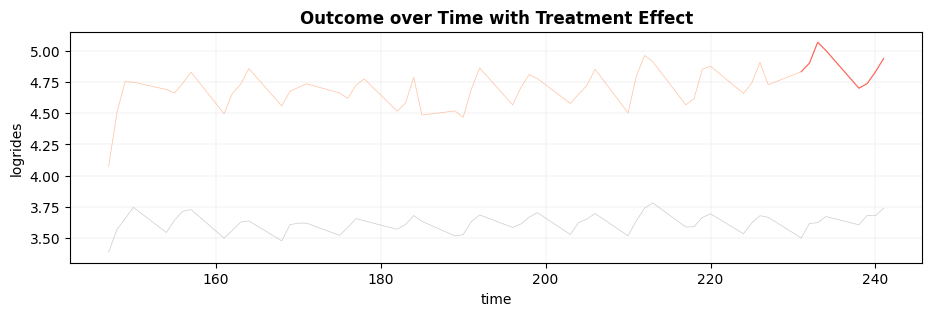

In [66]:
pf.panelview(pipes([drop_weekends])(panel),
             outcome="logrides", time="time", unit="id", treat="treat",
             collapse_to_cohort=True)

# Placebo Test

In [154]:
nweeks = (from_ymd(panel['date'].max()) - from_ymd(panel['date'].min())).days // 7
print(f"Panel has {nweeks} weeks.")

def placebo_dates(df, weekshift):
    df = df.sort_values('date')
    shift = df['date'].apply(from_ymd) + timedelta(days=7 * weekshift)
    df["treat"] = df['UCMP'] & (("2024-08-19" <= shift) & (shift <= "2024-08-22"))
    return df

Panel has 13 weeks.


In [155]:
placebos = [model_did(pipes([drop_weekends, partial(placebo_dates, weekshift=i)])(panel))
            for i in range(1, nweeks)]

In [156]:
pf.etable(placebos)

GT(_tbl_data=  __index_level_0__           __index_level_1__                    0  \
0              coef                       treat   0.059 <br> (0.097)   
1              coef   treat × transit ×  × bike  -0.037 <br> (0.162)   
2              coef  treat × transit ×  × train  -0.111 <br> (0.110)   
3                fe                          id                    -   
4                fe                        time                    -   
5             stats                Observations              110,026   
6             stats                          R²                0.972   

                     1                    2                     3  \
0  -0.025 <br> (0.052)   0.098 <br> (0.075)   -0.087 <br> (0.044)   
1   0.070 <br> (0.041)  -0.025 <br> (0.096)  0.141** <br> (0.046)   
2  -0.017 <br> (0.087)  -0.099 <br> (0.081)    0.092 <br> (0.060)   
3                    -                    -                     -   
4                    -                    -                     -   
5              110,026              110,026               110,026   
6                0.972                0.972                 0.972   

                      4                    5                    6  \
0   -0.090 <br> (0.048)   0.021 <br> (0.056)  -0.093 <br> (0.063)   
1  0.156** <br> (0.052)  -0.176 <br> (0.104)  -0.056 <br> (0.128)   
2    0.058 <br> (0.056)  -0.008 <br> (0.072)  -0.097 <br> (0.187)   
3                     -                    -                    -   
4                     -                    -                    -   
5               110,026              110,026              110,026   
6                 0.972                0.972                0.972   

                     7                    8                   9  \
0  -0.049 <br> (0.042)  -0.045 <br> (0.051)  0.010 <br> (0.072)   
1   0.058 <br> (0.083)   0.020 <br> (0.044)  0.023 <br> (0.082)   
2   0.056 <br> (0.051)  -0.058 <br> (0.079)  0.004 <br> (0.094)   
3                    -                    -                   -   
4                    -                    -                   -   
5              110,026              110,026             110,026   
6                0.972                0.972               0.972   

                    10                   11  
0  -0.005 <br> (0.033)  -0.064 <br> (0.093)  
1  -0.032 <br> (0.055)  -0.120 <br> (0.066)  
2   0.065 <br> (0.066)   0.027 <br> (0.032)  
3                    -                    -  
4                    -                    -  
5              110,026              110,026  
6                0.972                0.972  , _body=<great_tables._gt_data.Body object at 0x42a01cc40>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(6)'), column_align='center', column_width=None), ColInfo(var='6', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(7)'), column_align='center', column_width=None), ColInfo(var='7', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(8)'), column_align='center', column_width=None), ColInfo(var='8', type=<Co

# Coefficient Interpretation

## MDE

In [84]:
from src.power import panel_mde_ai

In [85]:
panel_mde_ai(panel, "transit", "id", "time", "rides", "treat")

,n_units,n_treated_obs,resid_sd,se,mdc,ar_mean,mds
transit,,,,,,,
bike,1596,172,0.384502,0.030741,0.089942,60.44186,935.039969
train,142,32,0.175380,0.032793,0.096225,2014.68750,6203.632739
uber,1257,160,0.425064,0.035024,0.103097,925.34375,15263.989583


In [137]:
import numpy as np, pandas as pd
from scipy import stats

def interpret(model):
    b, V = model.coef(), model._vcov
    names = list(b.index)

    combos = {
        "uber":  [names[0]],
        "bike":  [names[0], names[1]],
        "train": [names[0], names[2]],
    }

    rows = {}
    for k, cols in combos.items():
        w = pd.Series(0.0, index=names)
        w[cols] = 1
        est = w @ b
        se = np.sqrt(w.values @ V @ w.values)
        p = 2 * stats.t.sf(abs(est / se), model._df_t)
        ci = est + np.array([-1, 1]) * stats.t.ppf(0.975, model._df_t) * se
        rows[k] = dict(est=est, se=se, p=p, lo=ci[0], hi=ci[1],
                       est_pct=100 * (np.exp(est) - 1),
                       lo_pct=100 * (np.exp(ci[0]) - 1),
                       hi_pct=100 * (np.exp(ci[1]) - 1))

    return pd.DataFrame(rows).T

In [138]:
standard_model = model_did(pipes([drop_weekends])(panel))

In [139]:
interpret(standard_model)

,est,se,p,lo,hi,est_pct,lo_pct,hi_pct
uber,0.213932,0.087061,0.017181,0.039459,0.388405,23.853858,4.024766,47.462751
bike,0.284857,0.055010,0.000003,0.174614,0.395101,32.957254,19.078673,48.453380
train,0.340316,0.116153,0.004929,0.107539,0.573092,40.539097,11.353403,77.374351
